# Laboratory Exercise 1: Food Delivery

City Delivery is a delivery service that brings meals from restaurants across Macedonia to the door. Its pages are a stored snapshot in `data/site`, and the setup serves them from this machine, so every request stays on the local loopback address. The orders are synthetic and describe no real restaurant, courier, or customer.

Answer each request in the cells below it, and add as many cells as you need. The laboratory test asks for values and decisions that your notebook computes, so keep every result visible, run the notebook from top to bottom before you submit it, and make sure it runs on a machine without internet access.

## Setup

The cells in this section are written already. Run them before the tasks.

In [3]:
import json
import re
import threading
from functools import partial
from http.server import SimpleHTTPRequestHandler, ThreadingHTTPServer
from pathlib import Path
from urllib.parse import parse_qs, urljoin, urlparse

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from bs4 import BeautifulSoup, Tag
from playwright.async_api import async_playwright
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
# Every random step draws from this generator, so a rerun gives the same result.
rng = np.random.default_rng(2026)

In [4]:
# The course style.
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#1e2a24"]
GROUND, INK, GRID = "#ffffff", "#1e2a24", "#e2e6e4"
plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.facecolor": GROUND,
        "figure.constrained_layout.use": True,
        "savefig.facecolor": GROUND,
        "savefig.transparent": False,
        "font.family": "sans-serif",
        "font.sans-serif": ["Archivo", "DejaVu Sans"],
        "font.size": 12,
        "text.color": INK,
        "axes.facecolor": GROUND,
        "axes.edgecolor": INK,
        "axes.labelcolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.prop_cycle": plt.cycler(color=PALETTE),
        "grid.color": GRID,
        "xtick.color": INK,
        "ytick.color": INK,
        "legend.frameon": False,
        "image.cmap": "cividis",
    }
)
sns.set_palette(PALETTE)

In [5]:
# Every path is a file under the site directory.
class Service(SimpleHTTPRequestHandler):
    extensions_map = {
        **SimpleHTTPRequestHandler.extensions_map,
        ".html": "text/html; charset=utf-8",
    }

    def log_message(self, format: str, *args: object) -> None:
        pass


# Port 0 lets the system choose a free port, so a second running notebook never collides.
server = ThreadingHTTPServer(("127.0.0.1", 0), partial(Service, directory=DATA / "site"))
threading.Thread(target=server.serve_forever, daemon=True).start()
BASE = f"http://127.0.0.1:{server.server_port}/"
BASE

'http://127.0.0.1:37735/'

## Task 1: Collect the Orders

The service lists its delivered orders across several pages, and the first one is `catalogue/page-1.html` under `BASE`. Collect every order into a table named `orders`, with one row per order and these columns:

- `order_id`, the identifier of the order,
- `restaurant`, `cuisine`, and `city`,
- `distance` and `unit`, the distance from the restaurant to the door and the unit it is quoted in, exactly as the order states them,
- `minutes`, the minutes the delivery took,
- `slot`, `weather`, `payment`, and `rating`, the stars out of 5 that the customer gave, and
- `by_restaurant`, which is true when the restaurant delivered the order itself and false when a courier of the service did.

An order that does not state a field has a missing value in that column. Report how many orders the service lists and over how many pages they are spread.

In [6]:
COLUMNS = [
    "order_id", "restaurant", "cuisine", "city",
    "distance", "unit", "minutes", "slot",
    "weather", "payment", "rating", "by_restaurant",
]
rows = []
page_url = urljoin(BASE,"catalogue/page-1.html")
visited = set()
pages_count = 0

while page_url and page_url not in visited:
    visited.add(page_url)
    response = requests.get(page_url,timeout = 5)
    if response.status_code != 200:
        break
    pages_count += 1
    soup = BeautifulSoup(response.text,"lxml")
    order_cards = soup.select("article.card.order")

    for order in order_cards:
        row = {column: None for column in COLUMNS}
        row["order_id"] = order.get("data-id")

        restaurant = order.select_one("h2.title a, h2.title")
        if restaurant:
            row["restaurant"] = restaurant.getText(strip = True)
            
        for col in ["cuisine", "city", "slot", "weather", "payment", "rating"]:
            element = order.select_one(f".{col}")
            if element:
                value = element.get_text(" ", strip=True)
                if value not in ("", "-", "—"):
                    row[col] = value
        delivery = order.select_one(".delivery.figure, .delivery")
        if delivery:
            match = re.search(r"(\d+)\s*minutes?", delivery.get_text(" ", strip=True))
            if match:
                row["minutes"] = int(match.group(1))
        summary = order.select_one(".summary")
        if summary:
            match = re.search(r"([\d.]+)\s*(km|mi|m)\b", summary.get_text(" ", strip=True), re.IGNORECASE)
            if match:
                row["distance"] = float(match.group(1))
                row["unit"] = match.group(2)

        courier = order.select_one(".courier.muted, .courier")
        if courier:
            courier_text = courier.get_text(" ", strip=True).lower()
            if "restaurant" in courier_text:
                row["by_restaurant"] = True
            elif "courier" in courier_text or "service" in courier_text or "city delivery" in courier_text:
                row["by_restaurant"] = False

        if row["rating"] is not None:
            match = re.search(r"(\d+(?:\.\d+)?)", str(row["rating"]))
            if match:
                row["rating"] = float(match.group(1))

        rows.append(row)
    next_link = (
        soup.select_one("a[rel='next']")
        or soup.select_one("a.next")
        or soup.select_one("a[aria-label='Next']")
    )
    if next_link and next_link.get("href") and not next_link["href"].startswith("#"):
        page_url = urljoin(page_url, next_link["href"])
    else:
        page_url = None
orders = pd.DataFrame(rows, columns=COLUMNS)
print("Total orders:", len(orders))
print("Total pages:", pages_count)
print(orders.head())



Total orders: 192
Total pages: 16
  order_id    restaurant       cuisine    city  distance unit  minutes  \
0   310069    Salad Bowl         Salad  Skopje       5.0   km     23.0   
1   283894   Pizza House         Pizza  Skopje     650.0    m     30.0   
2   832866     Sushi Bar         Sushi  Skopje     700.0    m      NaN   
3   582431  Home Kitchen   Traditional  Skopje       2.7   km     25.0   
4   662069  Snack Corner  Small plates  Skopje       2.4   km     26.0   

         slot weather payment  rating  by_restaurant  
0  Late night   Clear    Cash     5.0          False  
1       Lunch   Clear    Card     3.0          False  
2       Lunch    Rain    Cash     3.0           True  
3       Lunch    Rain    Card     4.0          False  
4  Late night   Clear    Card     4.0           True  


In [7]:
async with async_playwright() as p:
    browser = await p.chromium.launch(headless = True)
    page = await browser.new_page()

    receipts_url = urljoin(BASE,"receipts.html")

    await page.goto(receipts_url)

    await page.locator("#receipts tr").nth(1).wait_for()

    receipts_count = await page.locator("#receipts-meta").inner_text()
    print("Page reports:", receipts_count)

    rows = await page.locator("#receipts tr").all()
    receipts = []
    for row in rows[1:]:
        cells = await row.locator("td").all_inner_texts()
        receipts.append({
            "order_id": int(cells[0]),
            "items": int(cells[1]),
            "total": int(cells[2]),
            "tip": int(cells[3])
        })
    
    await browser.close()
df = pd.DataFrame(receipts)
df["order_id"] = df["order_id"].astype(str)
df = df.drop_duplicates(subset = "order_id", keep = "first")
df.head()

df = orders.merge(df, on = "order_id",how = "left" ,validate = "one_to_one")
len(df),df.head()


Page reports: 193 receipts


(192,
   order_id    restaurant       cuisine    city  distance unit  minutes  \
 0   310069    Salad Bowl         Salad  Skopje       5.0   km     23.0   
 1   283894   Pizza House         Pizza  Skopje     650.0    m     30.0   
 2   832866     Sushi Bar         Sushi  Skopje     700.0    m      NaN   
 3   582431  Home Kitchen   Traditional  Skopje       2.7   km     25.0   
 4   662069  Snack Corner  Small plates  Skopje       2.4   km     26.0   
 
          slot weather payment  rating  by_restaurant  items  total  tip  
 0  Late night   Clear    Cash     5.0          False      2    770    0  
 1       Lunch   Clear    Card     3.0          False      4    860   60  
 2       Lunch    Rain    Cash     3.0           True      2    710    0  
 3       Lunch    Rain    Card     4.0          False      3   1240   60  
 4  Late night   Clear    Card     4.0           True      2    450   30  )

In [8]:
print(df.dtypes)
print(df["slot"].unique())
slot_order = ["Lunch","Dinner","Late night"]
df["slot"] = pd.Categorical(df["slot"],categories = slot_order,ordered = True)
print(df.dtypes)

order_id             str
restaurant           str
cuisine              str
city                 str
distance         float64
unit                 str
minutes          float64
slot                 str
weather              str
payment              str
rating           float64
by_restaurant       bool
items              int64
total              int64
tip                int64
dtype: object
<StringArray>
['Late night', 'Lunch', 'Dinner']
Length: 3, dtype: str
order_id              str
restaurant            str
cuisine               str
city                  str
distance          float64
unit                  str
minutes           float64
slot             category
weather               str
payment               str
rating            float64
by_restaurant        bool
items               int64
total               int64
tip                 int64
dtype: object


In [9]:
missing_counts = df.isna().sum().sort_values(ascending = False)
missing_counts
missing_rows = df[df.isna().any(axis = 1)]
len(missing_rows)

60

In [10]:
# Select only columns that have missing values
cols_with_na = df.columns[df.isna().any()]

# Calculate correlation between their boolean missing states (True/1 vs False/0)
na_Shadow_corr = df[cols_with_na].isna().corr()
print(na_Shadow_corr)

df["minutes_missing"] = df["minutes"].isna()
df["rating_missing"] = df["rating"].isna()
check_cols = ["by_restaurant", "slot", "weather", "payment", "city", "cuisine", "unit"]

for col in check_cols:
    print(f"=== Зависност од колоната: {col.upper()} ===")
    summary = df.groupby(col, dropna=False, observed=False).agg(
        Total_Orders=(col, "count"),
        Missing_Minutes=("minutes_missing", "sum"),
        Missing_Min_Pct=("minutes_missing", lambda x: (x.mean() * 100).round(2)),
        Missing_Rating=("rating_missing", "sum"),
        Missing_Rat_Pct=("rating_missing", lambda x: (x.mean() * 100).round(2))
    )
    print(summary)
    print("\n")

from scipy.stats import chi2_contingency

ct_min = pd.crosstab(df["minutes"].isna(),df["by_restaurant"])
chi2,p_min,_,_ = chi2_contingency(ct_min)
print(f"P-value (minutes vs by_restaurant): {p_min:.4e}")
# 2. Тест за rating и weather (каде што имаше најголема разлика од 9.7% vs 18.9%)
ct_rat = pd.crosstab(df["rating"].isna(), df["weather"])
chi2, p_rat, _, _ = chi2_contingency(ct_rat)
print(f"P-value (rating vs weather): {p_rat:.4f}") # Ќе добиеш ~ 0.1190 (не е значајно, бидејќи p > 0.05)


          minutes    rating
minutes  1.000000  0.028571
rating   0.028571  1.000000
=== Зависност од колоната: BY_RESTAURANT ===
               Total_Orders  Missing_Minutes  Missing_Min_Pct  Missing_Rating  \
by_restaurant                                                                   
False                   142               10             7.04              18   
True                     50               32            64.00               6   

               Missing_Rat_Pct  
by_restaurant                   
False                    12.68  
True                     12.00  


=== Зависност од колоната: SLOT ===
            Total_Orders  Missing_Minutes  Missing_Min_Pct  Missing_Rating  \
slot                                                                         
Lunch                 56               11            19.64               9   
Dinner                79               18            22.78               9   
Late night            57               13            22.81      

In [11]:
#3.3

In [12]:
unit_comparasion = df.groupby("unit")["distance"].describe().round(2)
print(unit_comparasion)


df["distance_km"] = np.where(df["unit"] == "m",df["distance"] / 1000.0 ,df["distance"])
print(df.groupby("unit")["distance_km"].describe().round(2))
print("\n=== Пример редови конвертирани од метри во километри ===")
print(df[df["unit"] == "m"][["distance", "unit", "distance_km"]].head())

      count    mean     std    min    25%    50%    75%    max
unit                                                          
km    162.0    3.23    1.28    1.3    2.3    2.9    4.1    8.0
m      30.0  531.67  201.07  150.0  362.5  550.0  687.5  900.0
      count  mean   std   min   25%   50%   75%  max
unit                                                
km    162.0  3.23  1.28  1.30  2.30  2.90  4.10  8.0
m      30.0  0.53  0.20  0.15  0.36  0.55  0.69  0.9

=== Пример редови конвертирани од метри во километри ===
    distance unit  distance_km
1      650.0    m         0.65
2      700.0    m         0.70
9      450.0    m         0.45
11     300.0    m         0.30
12     400.0    m         0.40


In [13]:
#3.4

/tmp/ipykernel_138782/1496972615.py:33: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


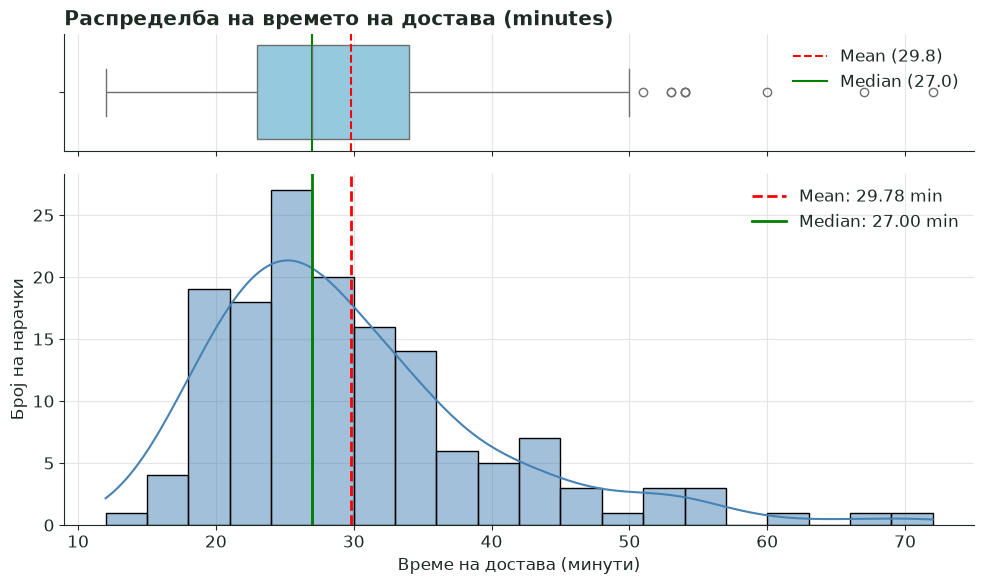

In [14]:
minutes_clean = df["minutes"].dropna()

mean_val = minutes_clean.mean()
median_val = minutes_clean.median()

#spread
std_val = minutes_clean.std()
iqr_val = minutes_clean.quantile(0.75) - minutes_clean.quantile(0.25)
min_val = minutes_clean.min()
max_val = minutes_clean.max()

skew_val = minutes_clean.skew()
kurt_val = minutes_clean.kurt()

fig, (ax_box, ax_hist) = plt.subplots(
    2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": (0.25, 0.75)}
)

# Горен дел: Boxplot (за медијана, IQR и outliers)
sns.boxplot(x=minutes_clean, ax=ax_box, color="skyblue")
ax_box.axvline(mean_val, color="red", linestyle="--", label=f"Mean ({mean_val:.1f})")
ax_box.axvline(median_val, color="green", linestyle="-", label=f"Median ({median_val:.1f})")
ax_box.set(xlabel="", title="Распределба на времето на достава (minutes)")
ax_box.legend(loc="upper right")

# Долен дел: Хистограм + KDE (за обликот на распределбата)
sns.histplot(minutes_clean, kde=True, ax=ax_hist, color="steelblue", bins=20)
ax_hist.axvline(mean_val, color="red", linestyle="--", linewidth=2, label=f"Mean: {mean_val:.2f} min")
ax_hist.axvline(median_val, color="green", linestyle="-", linewidth=2, label=f"Median: {median_val:.2f} min")
ax_hist.set(xlabel="Време на достава (минути)", ylabel="Број на нарачки")
ax_hist.legend()

plt.tight_layout()
plt.show()

In [15]:
#3.5

=== Споредба на времето на достава (minutes) по временски слот ===
            Count   Mean     SD  Median    IQR   Min   Max
slot                                                      
Lunch          45  28.93   9.61    27.0   8.00  12.0  54.0
Dinner         61  30.75   9.50    28.0  11.00  16.0  54.0
Late night     44  29.30  11.99    26.0   9.25  17.0  72.0


/tmp/ipykernel_138782/272198503.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_138782/272198503.py:29: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


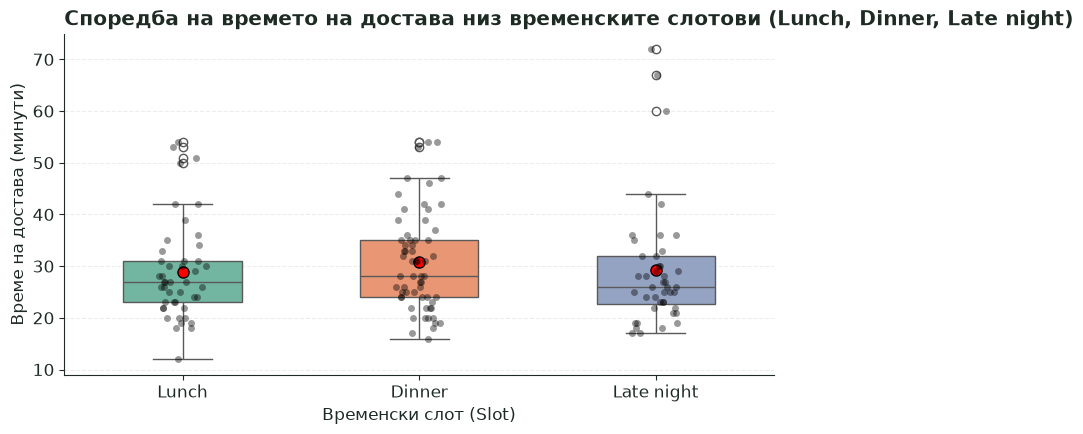

In [16]:
slot_comparison = df.groupby("slot", observed=False)["minutes"].agg(
    Count="count",
    Mean="mean",
    SD="std",
    Median="median",
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25),
    Min="min",
    Max="max"
).round(2)
print("=== Споредба на времето на достава (minutes) по временски слот ===")
print(slot_comparison)

sns.boxplot(
    data=df, x="slot", y="minutes", order=slot_order,
    palette="Set2", width=0.5, showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "black", "markersize": "8"}
)

# Додавање на поединечните нарачки како точки за да се гледа распределбата
sns.stripplot(
    data=df, x="slot", y="minutes", order=slot_order,
    color="black", alpha=0.4, jitter=True, size=5
)

plt.title("Споредба на времето на достава низ временските слотови (Lunch, Dinner, Late night)")
plt.xlabel("Временски слот (Slot)")
plt.ylabel("Време на достава (минути)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

In [17]:
#3.6

In [18]:
city_counts = df["city"].value_counts()


city_share = df["city"].value_counts(normalize=True) * 100


city_summary = pd.DataFrame({
    "orders": city_counts,
    "share_percent": city_share.round(2)
})

print(city_summary)

          orders  share_percent
city                           
Skopje        99          51.56
Tetovo        24          12.50
Kumanovo      22          11.46
Bitola        18           9.38
Ohrid         15           7.81
Prilep        14           7.29


In [19]:
# 3.7

Pearson Correlation (Линеарна сила): 0.8806 (p-value: 1.6002e-63)
Spearman Correlation (Монотона сила): 0.8691 (p-value: 5.3549e-60)


/tmp/ipykernel_138782/3966256070.py:20: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


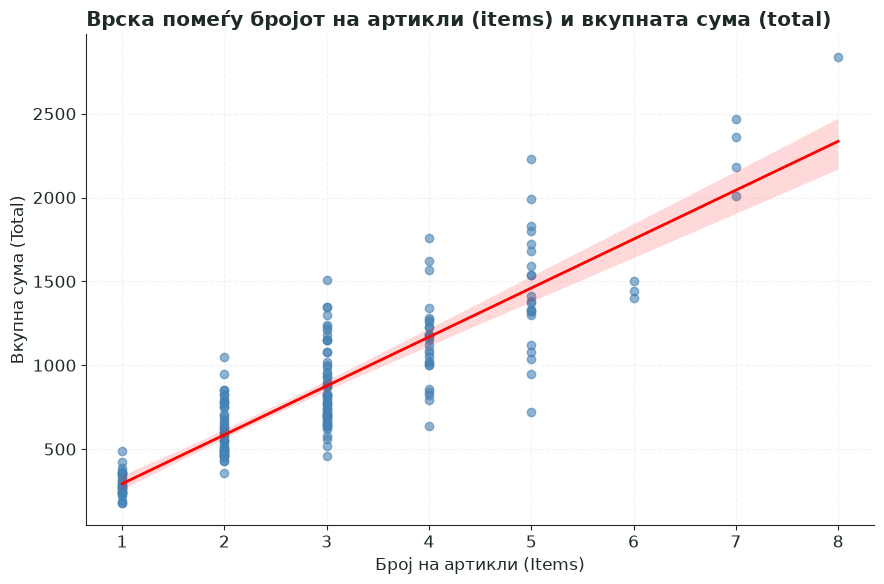

/tmp/ipykernel_138782/3966256070.py:29: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


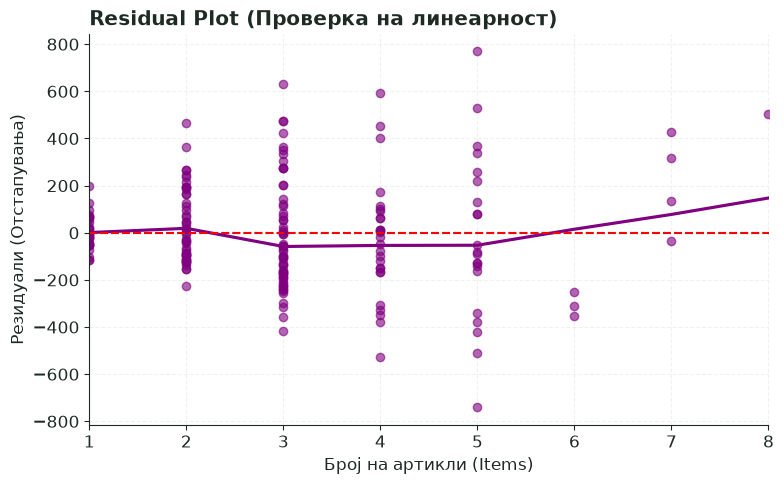

In [26]:
clean_data = df[["items","total"]].dropna()
from scipy.stats import pearsonr, spearmanr
pearson_corr, p_val_p = pearsonr(clean_data['items'], clean_data['total'])
spearman_corr, p_val_s = spearmanr(clean_data['items'], clean_data['total'])
print(f"Pearson Correlation (Линеарна сила): {pearson_corr:.4f} (p-value: {p_val_p:.4e})")
print(f"Spearman Correlation (Монотона сила): {spearman_corr:.4f} (p-value: {p_val_s:.4e})")
plt.figure(figsize=(9, 6))

# Цртање на scatter plot со линија на тренд
sns.regplot(
    data=df, x='items', y='total',
    scatter_kws={'alpha': 0.6, 'color': 'steelblue'},
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title('Врска помеѓу бројот на артикли (items) и вкупната сума (total)')
plt.xlabel('Број на артикли (Items)')
plt.ylabel('Вкупна сума (Total)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
plt.figure(figsize=(8, 5))
sns.residplot(data=df, x='items', y='total', lowess=True, color='purple', scatter_kws={'alpha': 0.6})
plt.axhline(0, color='red', linestyle='--')
plt.title('Residual Plot (Проверка на линеарност)')
plt.xlabel('Број на артикли (Items)')
plt.ylabel('Резидуали (Отстапувања)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
#3,8

In [30]:
num_cols = ["distance_km", "minutes", "rating", "items", "total", "tip"]
spearman_matrix = df[num_cols].corr(method="spearman")
print("=== Spearman Correlation Matrix ===")
print(spearman_matrix.round(4))
# Ја отстрануваме дијагоналата и дупликатите (земаме само горен триаголник од матрицата)
upper_tri = spearman_matrix.where(np.triu(np.ones(spearman_matrix.shape), k=1).astype(bool))

# Ги претвораме паровите во листа и ги подредуваме по апсолутна јачина (од најсилна кон најслаба)
pairs = upper_tri.unstack().dropna()
sorted_pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)

print("=== Сите парови подредени по јачина на Spearman корелација ===")
print(sorted_pairs.round(4))

# Го издвојуваме најсилниот пар
strongest_pair = sorted_pairs.index[0]
strongest_val = sorted_pairs.iloc[0]

print(f"\nНајсилно поврзан пар: '{strongest_pair[0]}' и '{strongest_pair[1]}' (Spearman r = {strongest_val:.4f})")

=== Spearman Correlation Matrix ===
             distance_km  minutes  rating   items   total     tip
distance_km       1.0000   0.5201 -0.2209  0.0321  0.0605  0.0185
minutes           0.5201   1.0000 -0.4153 -0.0664 -0.0358  0.0711
rating           -0.2209  -0.4153  1.0000  0.0819  0.0883 -0.0412
items             0.0321  -0.0664  0.0819  1.0000  0.8691  0.4228
total             0.0605  -0.0358  0.0883  0.8691  1.0000  0.4634
tip               0.0185   0.0711 -0.0412  0.4228  0.4634  1.0000
=== Сите парови подредени по јачина на Spearman корелација ===
total    items          0.8691
minutes  distance_km    0.5201
tip      total          0.4634
         items          0.4228
rating   minutes       -0.4153
         distance_km   -0.2209
total    rating         0.0883
items    rating         0.0819
tip      minutes        0.0711
items    minutes       -0.0664
total    distance_km    0.0605
tip      rating        -0.0412
total    minutes       -0.0358
items    distance_km    0.0321
tip  

In [ ]:
#3.9

In [31]:
import pandas as pd

# 1. Групираме по 'city' и 'slot' и пресметуваме број на валидни минути и медијана
city_slot_stats = df.groupby(["city", "slot"], observed=False)["minutes"].agg(
    Valid_Orders="count",   # Ги брои само нарачките каде 'minutes' НЕ Е NaN
    Median_Minutes="median"
).reset_index()

# 2. Ги филтрираме само комбинациите со најмалку 3 валидни нарачки
filtered_combos = city_slot_stats[city_slot_stats["Valid_Orders"] >= 3]

# 3. Ги подредуваме од највисока кон најниска медијана
sorted_combos = filtered_combos.sort_values(by="Median_Minutes", ascending=False)

print("=== Сите комбинации со >= 3 валидни нарачки (подредени по медијана) ===")
print(sorted_combos.to_string(index=False))

# 4. Издвојување на првата (најбавната) комбинација
top_combo = sorted_combos.iloc[0]
print(f"\nНајвисока медијана има комбинацијата: {top_combo['city']} - {top_combo['slot']} "
      f"(Медијана: {top_combo['Median_Minutes']:.2f} мин, од вкупно {top_combo['Valid_Orders']} нарачки со време).")

=== Сите комбинации со >= 3 валидни нарачки (подредени по медијана) ===
    city       slot  Valid_Orders  Median_Minutes
  Prilep     Dinner             5            35.0
  Tetovo      Lunch             3            34.0
Kumanovo     Dinner             6            33.5
  Tetovo Late night             5            32.0
   Ohrid Late night             3            32.0
Kumanovo      Lunch             8            29.5
  Tetovo     Dinner             8            29.5
  Bitola      Lunch             4            28.5
  Skopje     Dinner            35            28.0
  Prilep      Lunch             3            27.0
  Skopje Late night            22            26.0
   Ohrid     Dinner             5            26.0
  Bitola Late night             6            25.5
   Ohrid      Lunch             4            25.0
  Skopje      Lunch            23            24.0
Kumanovo Late night             5            23.0
  Prilep Late night             3            17.0

Највисока медијана има комб